# Свёртки и устройство CNN
Дополнение к статье 2.3. Нужен только NumPy. Выполните ячейки сверху вниз. Изображения синтетические, для проверки вычислений. Обучения и сравнения точности в этом примере нет.

## Один фильтр
Считаем взаимную корреляцию: шаг 1, без дополнения, одно смещение на весь фильтр.

In [1]:
import numpy as np

def conv2d(x, kernel, bias=0.0):
    x = np.asarray(x, dtype=float)
    kernel = np.asarray(kernel, dtype=float)
    if x.ndim != 2 or kernel.ndim != 2:
        raise ValueError("Нужны две двумерные таблицы")
    h, w = x.shape
    kh, kw = kernel.shape
    if min(kh, kw) < 1 or kh > h or kw > w:
        raise ValueError("Ядро должно помещаться во входе")
    out = np.empty((h-kh+1, w-kw+1))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            out[i, j] = (x[i:i+kh, j:j+kw] * kernel).sum() + bias
    return out

x = np.tile([0, 0, 1, 1], (4, 1))
kernel = np.array([[-1, 1], [-1, 1]])
y = conv2d(x, kernel)
print(y)
assert np.array_equal(y, np.tile([0, 2, 0], (3, 1)))

[[0. 2. 0.]
 [0. 2. 0.]
 [0. 2. 0.]]


## Сдвиг и направление границы
Перед запуском предскажите, как изменится ответ. Проверим также однородную картинку, минимальный вход и слишком большое ядро.

In [2]:
shifted = np.tile([0, 0, 0, 1], (4, 1))
assert np.array_equal(conv2d(shifted, kernel), np.tile([0, 0, 2], (3, 1)))
assert np.array_equal(conv2d(1-x, kernel), -y)
assert np.array_equal(conv2d(np.ones((4, 4)), kernel), np.zeros((3, 3)))
assert conv2d([[2]], [[3]], bias=1).item() == 7
try:
    conv2d([[1]], np.ones((2, 2)))
except ValueError:
    print("Слишком большое ядро отклонено")
else:
    raise AssertionError("Нужна проверка размера ядра")
print(conv2d(shifted, kernel))

Слишком большое ядро отклонено
[[0. 0. 2.]
 [0. 0. 2.]
 [0. 0. 2.]]


## ReLU и пулинг
Окна 2 × 2 с шагом 2. Эта реализация пулинга принимает только непустые таблицы с чётными сторонами.

In [3]:
assert np.array_equal(np.maximum([-2, 0, 3], 0), [0, 0, 3])

def maxpool2(x):
    x = np.asarray(x)
    if x.ndim != 2 or any(n == 0 or n % 2 for n in x.shape):
        raise ValueError("Нужны непустые чётные стороны")
    h, w = x.shape
    return x.reshape(h//2, 2, w//2, 2).max(axis=(1, 3))

a = np.array([[1, 3, 2, 0], [4, 2, 1, 5],
              [0, 1, 7, 2], [2, 3, 4, 6]])
print(maxpool2(a))
assert np.array_equal(maxpool2(a), [[4, 5], [3, 7]])
assert maxpool2(-np.ones((2, 2))).item() == -1

[[4 5]
 [3 7]]


## Формы данных
Размеры указаны в порядке: каналы, высота, ширина. Проверим, как они меняются при прохождении через сеть.

In [4]:
def size(n, k, p=0, s=1):
    return (n + 2*p - k)//s + 1

assert size(4, 2) == 3
assert size(28, 3, 1, 2) == 14
shape = (1, 28, 28)
print("Вход:", shape)
for channels in [8, 16]:
    _, h, w = shape
    shape = (channels, size(h, 3, 1), size(w, 3, 1))
    print("Свёртка и ReLU:", shape)
    shape = (channels, size(shape[1], 2, s=2), size(shape[2], 2, s=2))
    print("Пулинг:", shape)
assert shape == (16, 7, 7)
print("После разворачивания:", int(np.prod(shape)))

Вход: (1, 28, 28)
Свёртка и ReLU: (8, 28, 28)
Пулинг: (8, 14, 14)
Свёртка и ReLU: (16, 14, 14)
Пулинг: (16, 7, 7)
После разворачивания: 784


## Самостоятельно
1. Поверните фильтр для поиска горизонтальной границы. Вход: две чёрные строки над двумя белыми. Ожидайте среднюю строку из двоек.
2. Увеличьте число фильтров первого слоя до 12. Какие формы изменятся? Перед первым пулингом будет 12 × 28 × 28, после него — 12 × 14 × 14. Во второй свёртке по-прежнему создаются 16 карт.
3. Уберите дополнение в обеих свёртках. После первого пулинга будет 8 × 13 × 13, после второго — 16 × 5 × 5. Перед последним слоем останется 400 чисел.

Для сравнения точности потребуется отдельный опыт: одинаковое разделение данных, обучение моделей, выбор настроек по валидации и итоговая проверка на тесте.

## Два фильтра на одном изображении
Фильтр А сравнивает левую и правую части окна, фильтр Б — верхнюю и нижнюю. Оба работают с тем же изображением 4 × 4, с шагом 1, без дополнения и смещения.

В окне на вертикальной границе верхняя и нижняя строки совпадают: 0, 1. Поэтому фильтр А даёт отклик 2, а фильтр Б — 0. Проверьте это вручную перед запуском.

In [5]:
image = np.tile([0, 0, 1, 1], (4, 1))
kernel_v = np.array([[-1, 1], [-1, 1]])
kernel_h = np.array([[-1, -1], [1, 1]])
map_v = conv2d(image, kernel_v)
map_h = conv2d(image, kernel_h)
assert np.array_equal(map_v, np.tile([0, 2, 0], (3, 1)))
assert np.array_equal(map_h, np.zeros((3, 3)))
patch = image[:2, 1:3]
assert np.array_equal(patch, [[0, 1], [0, 1]])
assert (patch * kernel_v).sum() == 2
assert (patch * kernel_h).sum() == 0
print("Изображение:", image, sep="\n")
print("Фильтр А:", kernel_v, "Карта А:", map_v, sep="\n")
print("Фильтр Б:", kernel_h, "Карта Б:", map_h, sep="\n")
# На горизонтальной границе отклики меняются местами.
assert np.array_equal(conv2d(image.T, kernel_v), np.zeros((3, 3)))
assert np.array_equal(conv2d(image.T, kernel_h), [[0, 0, 0], [2, 2, 2], [0, 0, 0]])

Изображение:
[[0 0 1 1]
 [0 0 1 1]
 [0 0 1 1]
 [0 0 1 1]]
Фильтр А:
[[-1  1]
 [-1  1]]
Карта А:
[[0. 2. 0.]
 [0. 2. 0.]
 [0. 2. 0.]]
Фильтр Б:
[[-1 -1]
 [ 1  1]]
Карта Б:
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]


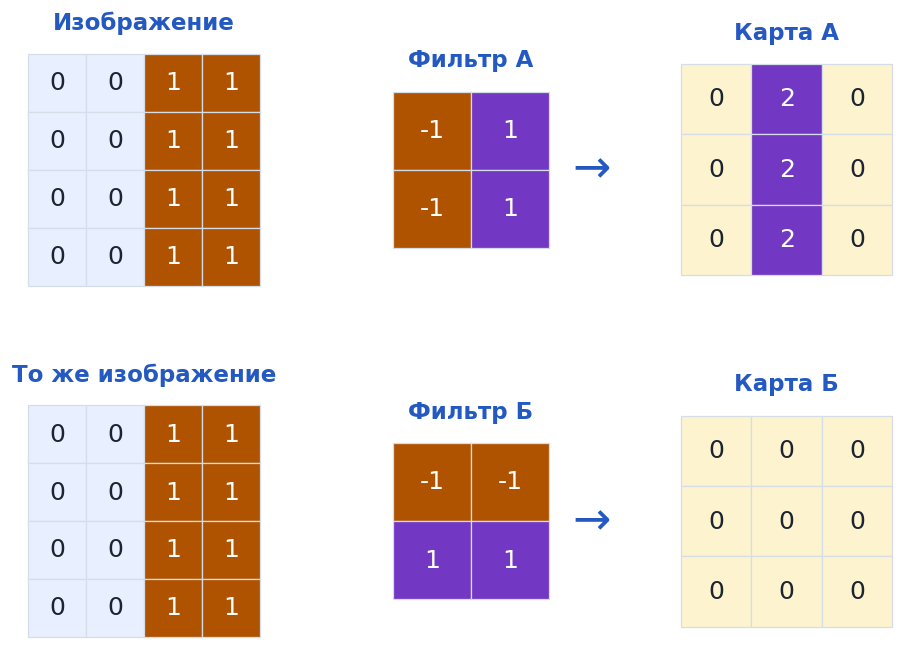

## Дополнительная задача: вычисление свёртки
Это необязательное упражнение для тех, кто хочет реализовать рассмотренный приём.

**Условие.** Даны таблица целых чисел и фильтр 2 × 2. Вычислите карту откликов с шагом 1, без дополнения и смещения. В каждом положении умножьте соответствующие элементы и сложите произведения.

**Вход.** В первой строке записаны высота H и ширина W. Далее идут H строк по W чисел, затем две строки по два числа — веса фильтра.

**Ограничения.** 2 ≤ H, W ≤ 30; значения изображения и фильтра — целые числа от −9 до 9.

**Выход.** H − 1 строк по W − 1 чисел — полученная карта.

Пример входа:
```text
3 3
0 0 1
0 0 1
0 0 1
-1 1
-1 1
```
Ответ:
```text
0 2
0 2
```
Сначала проверьте пример вручную. Затем рассмотрите минимальное изображение 2 × 2: на выходе будет одно число. Проверьте также нулевой фильтр и отрицательные значения.

Это подготовленное условие; задача на платформе ещё не опубликована.

## Самопроверка




### 1. Сколько чисел описывают один пиксель RGB-изображения и что они означают?

A. Одно число — общая яркость.

B. Три числа — красная, зелёная и синяя составляющие.

C. Два числа — высота и ширина.

D. Четыре числа — значения соседних пикселей.




### 2. Почему при перемещении фильтра не нужно задавать новые веса?

A. В каждом положении используются случайные веса.

B. Весами служат значения текущего окна.

C. Одна таблица весов применяется во всех положениях.

D. Веса нужны только для первого окна.




### 3. Чему равен отклик нашего фильтра на окне, в котором все значения равны 1?

A. 0

B. 1

C. 2

D. 4




### 4. В ручном примере границу сдвинули на один пиксель вправо. Какой станет верхняя строка карты?

A. $(2,0,0)$

B. $(0,2,0)$

C. $(2,2,2)$

D. $(0,0,2)$




### 5. Слой применяет к одному изображению несколько фильтров. Должны ли их карты совпасть?

A. Да, карты всегда совпадают.

B. Нет, разные веса могут давать разные карты.

C. Да, если размеры фильтров одинаковы.

D. Нет, размеры карт обязательно различаются.




### 6. Что ReLU сделает со строкой $(-3,2,0)$? Изменится ли длина строки?

A. $(-3,2,0)$; длина не изменится.

B. $(0,2)$; длина уменьшится.

C. $(0,2,0)$; длина не изменится.

D. $(3,2,0)$; длина не изменится.




### 7. Квадрат пулинга содержит числа 1, 3, 4 и 2. Что останется после максимального пулинга? Можно ли восстановить все числа?

A. Останется 4; восстановить остальные числа нельзя.

B. Останется 4; все числа можно восстановить.

C. Останется 10; все числа можно восстановить.

D. Останется 1; восстановить остальные числа нельзя.




### 8. На строке из пяти клеток окно шириной 3 перемещается с шагом 2, без дополнения. Сколько положений допустимо?

A. Одно.

B. Два.

C. Три.

D. Пять.




### 9. Максимальный пулинг $2\times2$ с шагом 2 получает восемь карт размером $14\times14$. Сколько карт и какого размера он вернёт?

A. Четыре карты $7\times7$.

B. Восемь карт $14\times14$.

C. Шестнадцать карт $7\times7$.

D. Восемь карт $7\times7$.




### 10. Гарантирует ли применение свёрток, что сеть одинаково распознает изображение после любого поворота?

A. Да, при любом повороте.

B. Да, если в сети есть пулинг.

C. Нет, поворот меняет расположение пикселей в окне.

D. Да, если изображение состоит из одного канала.




## Подсказки и решения

### Вопрос 1

**Подсказка**


Вспомните названия каналов.



**Решение**


**B.** Три числа — красная, зелёная и синяя составляющие. вместе они задают цвет одного пикселя.



### Вопрос 2

**Подсказка**


Меняется участок изображения.



**Решение**


**C.** Один фильтр использует одну таблицу весов во всех положениях. это позволяет искать одну деталь в разных частях изображения.



### Вопрос 3

**Подсказка**


Сложите два отрицательных и два положительных слагаемых.



**Решение**


**A.** $-1+1-1+1=0$. на однородном участке отклики этого фильтра равны нулю.



### Вопрос 4

**Подсказка**


Проверьте три положения окна.



**Решение**


**D.** $(0,0,2)$ вместо $(0,2,0)$. отклик переместился вслед за границей.



### Вопрос 5

**Подсказка**


У фильтров могут различаться веса.



**Решение**


**B.** Нет, разные фильтры могут давать разные карты. каждый из них реагирует на своё сочетание значений в окне.



### Вопрос 6

**Подсказка**


Замените только отрицательные значения.



**Решение**


**C.** Получится $(0,2,0)$; длина не изменится. ReLU действует на каждое значение отдельно.



### Вопрос 7

**Подсказка**


Выберите максимум.



**Решение**


**A.** Останется 4; восстановить остальные значения нельзя. разные исходные квадраты могут иметь один и тот же максимум.



### Вопрос 8

**Подсказка**


Отметьте начало окна в первой и третьей клетках.



**Решение**


**B.** Два положения. следующее окно вышло бы за границу строки.



### Вопрос 9

**Подсказка**


Каналы обрабатываются отдельно.



**Решение**


**D.** Восемь карт размером $7\times7$. пулинг уменьшает высоту и ширину, сохраняя число каналов.



### Вопрос 10

**Подсказка**


Подумайте, что изменится внутри окна.



**Решение**


**C.** Нет. при повороте расположение пикселей меняется, и те же фильтры могут дать другие отклики.



